# Day 5 — Neural Networks: Perceptron, Backpropagation & Keras
**System 7 · Week 3 · Commit: `day-19-neural-networks`**

**Module C:** perceptrons, neurons/weights/biases, activation functions, forward & backpropagation, loss and gradient descent, SGD vs Adam, the Keras workflow.

**Practice questions solved today:** Q14, Q15 · **Module task:** predict student results with a neural network · **Learning topics:** Activation functions; Learning rate, batch size, epochs

In [1]:
import os; os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json, warnings, random
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report, ConfusionMatrixDisplay, f1_score
warnings.filterwarnings("ignore")
RANDOM_STATE = 42
def set_seed(s=RANDOM_STATE): random.seed(s); np.random.seed(s); tf.random.set_seed(s); keras.utils.set_random_seed(s)
set_seed(); R = {}
print("TensorFlow", tf.__version__)

I0000 00:00:1793518640.423279   11460 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793518641.585024   11460 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0


## 1. The building block — one neuron
A neuron computes a **weighted sum plus a bias**, then passes it through an **activation function**:

$$ a = f(\mathbf{w}\cdot\mathbf{x} + b) $$

* **weights** `w` – how much each input matters (learned),
* **bias** `b` – shifts the decision threshold (learned),
* **activation** `f` – adds non-linearity; without it, a stack of layers collapses into a single linear model.

**Forward propagation** = push the inputs through the layers to get a prediction. **Backpropagation** = use the chain rule to find how much each weight contributed to the loss, then **gradient descent** nudges each weight against its gradient: `w ← w − lr · ∂Loss/∂w`.

In [2]:
x = np.array([0.5, -1.2, 3.0]); w = np.array([0.4, 0.3, -0.2]); b = 0.1
z = np.dot(w, x) + b
print(f"z = w·x + b = {z:.3f}\nsigmoid(z) = {1/(1+np.exp(-z)):.3f} | relu(z) = {max(0, z):.3f} | tanh(z) = {np.tanh(z):.3f}")

z = w·x + b = -0.660
sigmoid(z) = 0.341 | relu(z) = 0.000 | tanh(z) = -0.578


## Learning topic — Activation functions
| Function | Formula | Output range | Typical use |
|---|---|---|---|
| **ReLU** | max(0, z) | [0, ∞) | Default for **hidden layers**: cheap, avoids vanishing gradients |
| **Sigmoid** | 1/(1+e⁻ᶻ) | (0, 1) | **Output of binary classification** (probability) |
| **Softmax** | eᶻⁱ/Σeᶻʲ | (0, 1), sums to 1 | **Output of multiclass classification** |
| **Tanh** | (eᶻ−e⁻ᶻ)/(eᶻ+e⁻ᶻ) | (−1, 1) | Zero-centred alternative in some hidden layers/RNNs |

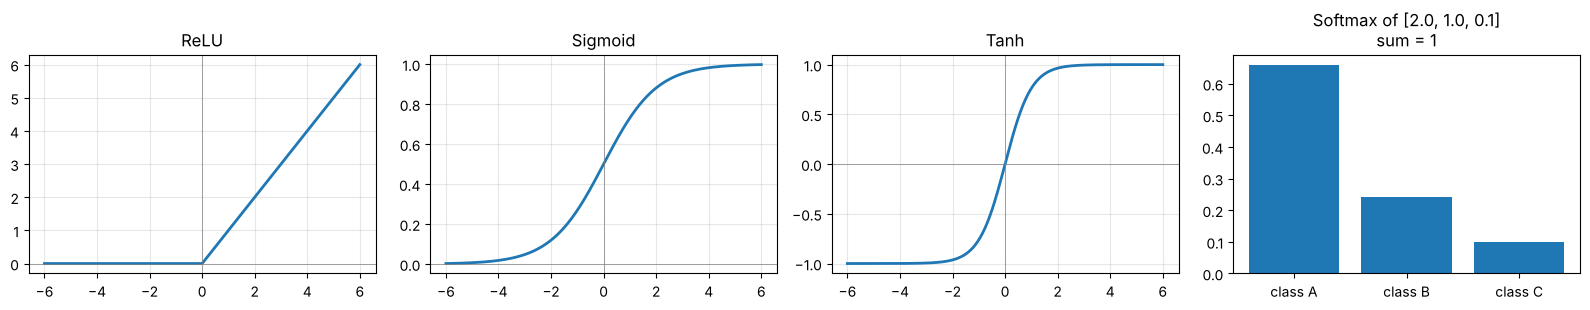

Softmax probabilities: [0.659 0.242 0.099]


In [3]:
z = np.linspace(-6, 6, 400)
fig, ax = plt.subplots(1, 4, figsize=(16, 3.2))
for a, (n, f) in zip(ax[:3], [("ReLU", lambda z: np.maximum(0, z)), ("Sigmoid", lambda z: 1/(1+np.exp(-z))), ("Tanh", np.tanh)]):
    a.plot(z, f(z), lw=2); a.axhline(0, c="gray", lw=.5); a.axvline(0, c="gray", lw=.5); a.set_title(n); a.grid(alpha=.3)
logits = np.array([2.0, 1.0, 0.1]); sm = np.exp(logits) / np.exp(logits).sum()
ax[3].bar(["class A", "class B", "class C"], sm); ax[3].set_title(f"Softmax of {logits.tolist()}\nsum = {sm.sum():.0f}"); plt.tight_layout(); plt.show()
print("Softmax probabilities:", sm.round(3))

## Q14 (Easy) — A single perceptron in NumPy that learns the AND gate
The perceptron learning rule: for each sample, `error = target − prediction`, then `w += lr · error · x` and `b += lr · error`. It uses a **step** activation (output 1 if `w·x + b > 0`, else 0). AND is linearly separable, so training is guaranteed to converge.

Mistakes per epoch: [2, 2, 2, 2, 2, 2, 3, 2, 1, 0] -> converged after 10 epochs
Learned weights: [0.152 0.08 ] | bias: -0.2

 x1 x2 | AND | predicted
 0  0  |  0  |  0
 0  1  |  0  |  0
 1  0  |  0  |  0
 1  1  |  1  |  1

✅ Perceptron learned AND


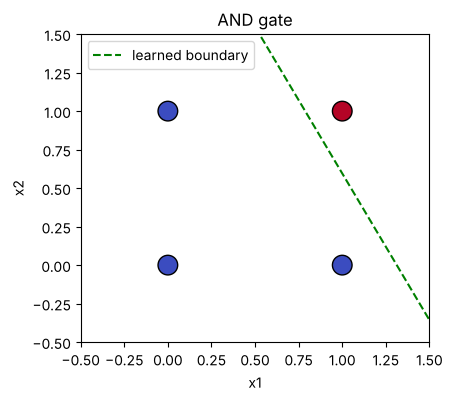

In [4]:
class Perceptron:
    def __init__(self, n_inputs, lr=0.1, seed=RANDOM_STATE):
        rng = np.random.default_rng(seed); self.w = rng.normal(0, .5, n_inputs); self.b = 0.0; self.lr = lr
    def predict(self, X): return (X @ self.w + self.b > 0).astype(int)          # step activation
    def fit(self, X, y, epochs=20):
        history = []
        for ep in range(epochs):
            errors = 0
            for xi, ti in zip(X, y):
                err = ti - self.predict(xi.reshape(1, -1))[0]
                self.w += self.lr * err * xi; self.b += self.lr * err; errors += int(err != 0)
            history.append(errors)
            if errors == 0: break                                              # converged
        return history

X_and = np.array([[0, 0], [0, 1], [1, 0], [1, 1]]); y_and = np.array([0, 0, 0, 1])
p = Perceptron(2); hist = p.fit(X_and, y_and)
print("Mistakes per epoch:", hist, f"-> converged after {len(hist)} epochs")
print("Learned weights:", p.w.round(3), "| bias:", round(p.b, 3))
print("\n x1 x2 | AND | predicted"); [print(f" {a}  {b}  |  {t}  |  {o}") for (a, b), t, o in zip(X_and, y_and, p.predict(X_and))]
assert (p.predict(X_and) == y_and).all(); print("\n✅ Perceptron learned AND")
R["q14"] = {"epochs": len(hist), "w": p.w.round(3).tolist(), "b": round(p.b, 3)}

xx = np.linspace(-.5, 1.5, 100); fig, ax = plt.subplots(figsize=(4.5, 4))
ax.scatter(*X_and.T, c=y_and, cmap="coolwarm", s=200, edgecolor="k"); ax.plot(xx, -(p.w[0]*xx + p.b)/p.w[1], "g--", label="learned boundary")
ax.set(xlim=(-.5, 1.5), ylim=(-.5, 1.5), xlabel="x1", ylabel="x2", title="AND gate"); ax.legend(); plt.show()

In [5]:
# A single perceptron cannot learn XOR (not linearly separable) - why we need hidden layers
y_xor = np.array([0, 1, 1, 0]); px = Perceptron(2); h = px.fit(X_and, y_xor, epochs=100)
print("XOR accuracy with one perceptron:", (px.predict(X_and) == y_xor).mean(), "| mistakes in last epoch:", h[-1])

XOR accuracy with one perceptron: 0.25 | mistakes in last epoch: 4


### Forward + backpropagation from scratch (2-layer network solving XOR)
A hidden layer lets the network bend the boundary. Here is the full loop in NumPy: forward pass → binary cross-entropy loss → backward pass (chain rule) → gradient-descent update.

XOR predictions: [0 1 1 0] | targets: [0 1 1 0] | final loss: 0.0009


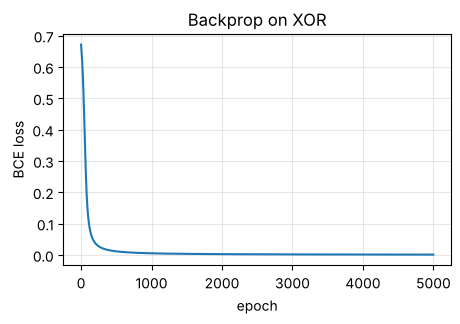

In [6]:
rng = np.random.default_rng(1)
W1, b1 = rng.normal(0, 1, (2, 4)), np.zeros((1, 4)); W2, b2 = rng.normal(0, 1, (4, 1)), np.zeros((1, 1))
sig = lambda z: 1 / (1 + np.exp(-z)); Y = y_xor.reshape(-1, 1); lr = 0.5; losses = []
for epoch in range(5000):
    # forward
    h = np.tanh(X_and @ W1 + b1); out = sig(h @ W2 + b2)
    loss = -np.mean(Y*np.log(out + 1e-9) + (1-Y)*np.log(1-out + 1e-9)); losses.append(loss)
    # backward (chain rule)
    d_out = (out - Y) / len(X_and)                 # dLoss/dz2 for sigmoid + BCE
    dW2, db2 = h.T @ d_out, d_out.sum(0, keepdims=True)
    d_h = (d_out @ W2.T) * (1 - h**2)              # tanh'(z) = 1 - tanh^2
    dW1, db1 = X_and.T @ d_h, d_h.sum(0, keepdims=True)
    # gradient-descent update
    W1 -= lr*dW1; b1 -= lr*db1; W2 -= lr*dW2; b2 -= lr*db2
pred = (out > .5).astype(int).ravel()
print("XOR predictions:", pred, "| targets:", y_xor, "| final loss:", round(losses[-1], 4))
plt.figure(figsize=(5, 3)); plt.plot(losses); plt.xlabel("epoch"); plt.ylabel("BCE loss"); plt.title("Backprop on XOR"); plt.grid(alpha=.3); plt.show()
R["xor_backprop"] = {"final_loss": round(float(losses[-1]), 4), "correct": bool((pred == y_xor).all())}

## Q15 (Medium) — Keras Sequential on tabular data: loss curves and SGD vs Adam
**Keras workflow:** 1) prepare data → 2) `Sequential([...])` → 3) `compile(optimizer, loss, metrics)` → 4) `fit` → 5) `evaluate`/`predict`.

* **SGD** updates weights with a single fixed learning rate. Simple, but slow and sensitive to the learning rate.
* **Adam** keeps running averages of the gradient and its square, giving each weight its own adaptive step — usually converges faster with little tuning.
Dataset: breast cancer (30 numeric features, binary target).

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,925 (7.52 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,284 (5.02 KB)

                 test_loss  test_acc  final_train_loss  final_val_loss  \
SGD (lr=0.01)       0.1605    0.9211            0.1080          0.1129   
Adam (lr=0.001)     0.0912    0.9649            0.0309          0.0380   

                 epoch_val_acc>=95%  
SGD (lr=0.01)                  31.0  
Adam (lr=0.001)                13.0  


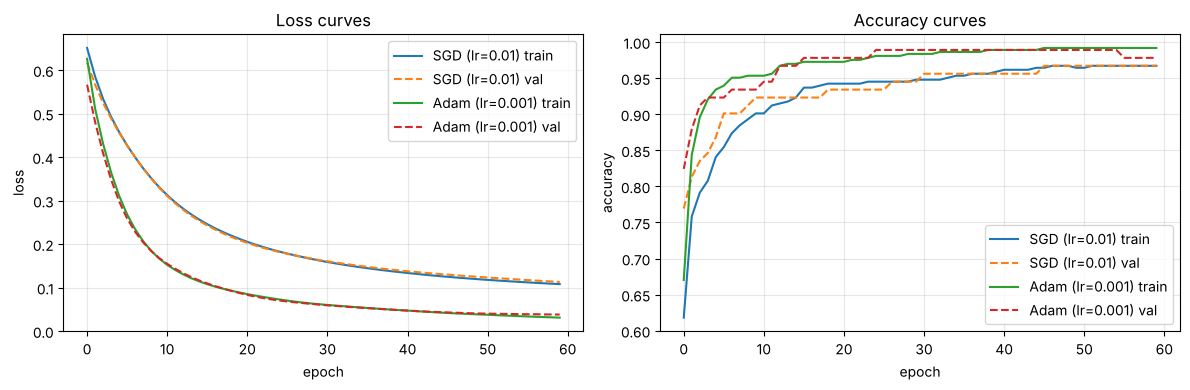

In [7]:
bc = load_breast_cancer(); Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(bc.data, bc.target, test_size=.2, stratify=bc.target, random_state=RANDOM_STATE)
sc = StandardScaler().fit(Xb_tr); Xb_tr_s, Xb_te_s = sc.transform(Xb_tr), sc.transform(Xb_te)

def build(opt):
    set_seed()
    m = keras.Sequential([layers.Input(shape=(30,)), layers.Dense(16, activation="relu"), layers.Dense(8, activation="relu"), layers.Dense(1, activation="sigmoid")])
    m.compile(optimizer=opt, loss="binary_crossentropy", metrics=["accuracy"]); return m

histories, results = {}, {}
for name, opt in [("SGD (lr=0.01)", keras.optimizers.SGD(0.01)), ("Adam (lr=0.001)", keras.optimizers.Adam(0.001))]:
    m = build(opt); h = m.fit(Xb_tr_s, yb_tr, validation_split=.2, epochs=60, batch_size=32, verbose=0)
    loss, acc = m.evaluate(Xb_te_s, yb_te, verbose=0); histories[name] = h.history
    first = int(np.argmax(np.array(h.history["val_accuracy"]) >= .95)) + 1 if max(h.history["val_accuracy"]) >= .95 else None
    results[name] = {"test_loss": loss, "test_acc": acc, "final_train_loss": h.history["loss"][-1], "final_val_loss": h.history["val_loss"][-1], "epoch_val_acc>=95%": first}
m.summary()
print(pd.DataFrame(results).T.round(4))
R["q15"] = {k: {kk: (round(vv, 4) if vv is not None else None) for kk, vv in v.items()} for k, v in results.items()}

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, h in histories.items():
    ax[0].plot(h["loss"], label=f"{name} train"); ax[0].plot(h["val_loss"], "--", label=f"{name} val")
    ax[1].plot(h["accuracy"], label=f"{name} train"); ax[1].plot(h["val_accuracy"], "--", label=f"{name} val")
ax[0].set(xlabel="epoch", ylabel="loss", title="Loss curves"); ax[1].set(xlabel="epoch", ylabel="accuracy", title="Accuracy curves")
for a in ax: a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Reading the curves:** Adam's loss drops much faster in the first epochs than plain SGD at the same number of epochs; SGD is still improving at the end. With more epochs or a bigger learning rate (or momentum) SGD would catch up — Adam simply needs less tuning. A growing gap between train and validation loss would signal overfitting.

---
# Module C practical task — Predict student results with a neural network
**Goal:** predict whether a student will **Pass or Fail** from study habits and background, using a Keras network with proper preprocessing, early stopping and an honest comparison against a simple baseline.
Dataset: `students.csv` (generated on Day 2; copied into this folder).

Input features after preprocessing: 15 | Pass rate: 0.758


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 32)             │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,057 (4.13 KB)

 Trainable params: 1,057 (4.13 KB)

 Non-trainable params: 0 (0.00 B)

Stopped at epoch 30 (best epoch 15)


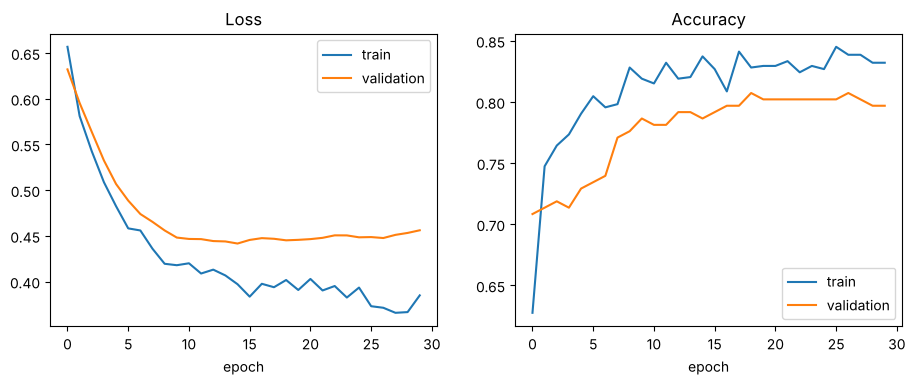

In [8]:
students = pd.read_csv("students.csv")
num_cols = ["study_hours", "attendance", "prev_gpa", "sleep_hours", "age"]; cat_cols = ["parent_edu", "internet", "tutoring", "school_type"]
X, y = students[num_cols + cat_cols], (students.result == "Pass").astype(int).values
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=.2, stratify=y, random_state=RANDOM_STATE)
prep = ColumnTransformer([("num", StandardScaler(), num_cols), ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)])
Xtr, Xte = prep.fit_transform(X_tr).astype("float32"), prep.transform(X_te).astype("float32")
print("Input features after preprocessing:", Xtr.shape[1], "| Pass rate:", y.mean().round(3))

def student_net(lr=1e-3, units=(32, 16), dropout=.2):
    set_seed(); m = keras.Sequential([layers.Input(shape=(Xtr.shape[1],))])
    for u in units: m.add(layers.Dense(u, activation="relu")); m.add(layers.Dropout(dropout))
    m.add(layers.Dense(1, activation="sigmoid")); m.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy", metrics=["accuracy", keras.metrics.AUC(name="auc")]); return m

model = student_net(); model.summary()
es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)
hist = model.fit(Xtr, y_tr, validation_split=.2, epochs=200, batch_size=32, callbacks=[es], verbose=0)
print(f"Stopped at epoch {len(hist.history['loss'])} (best epoch {int(np.argmin(hist.history['val_loss']))+1})")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(hist.history["loss"], label="train"); ax[0].plot(hist.history["val_loss"], label="validation"); ax[0].set(title="Loss", xlabel="epoch"); ax[0].legend()
ax[1].plot(hist.history["accuracy"], label="train"); ax[1].plot(hist.history["val_accuracy"], label="validation"); ax[1].set(title="Accuracy", xlabel="epoch"); ax[1].legend(); plt.show()

          Neural network  Logistic Regression (baseline)
Accuracy          0.8167                          0.8167
F1                0.8854                          0.8830
ROC-AUC           0.8354                          0.8365

               precision    recall  f1-score   support

        Fail       0.68      0.45      0.54        58
        Pass       0.84      0.93      0.89       182

    accuracy                           0.82       240
   macro avg       0.76      0.69      0.71       240
weighted avg       0.80      0.82      0.80       240



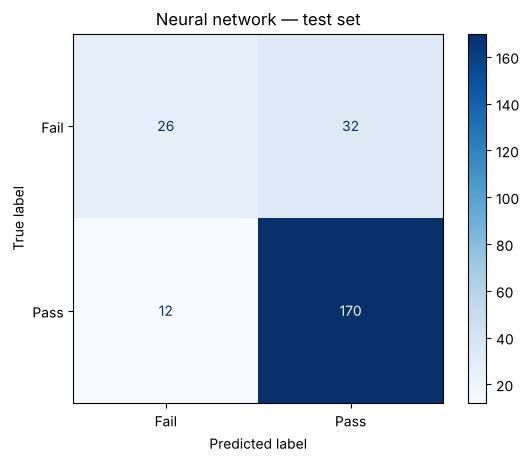

New student 1: P(pass) = 0.99 -> Pass
New student 2: P(pass) = 0.05 -> Fail


In [9]:
proba = model.predict(Xte, verbose=0).ravel(); pred = (proba > .5).astype(int)
base = LogisticRegression(max_iter=1000).fit(Xtr, y_tr); bp = base.predict(Xte); bpr = base.predict_proba(Xte)[:, 1]
tbl = pd.DataFrame({"Neural network": [accuracy_score(y_te, pred), f1_score(y_te, pred), roc_auc_score(y_te, proba)],
                    "Logistic Regression (baseline)": [accuracy_score(y_te, bp), f1_score(y_te, bp), roc_auc_score(y_te, bpr)]}, index=["Accuracy", "F1", "ROC-AUC"]).round(4)
print(tbl); print("\n", classification_report(y_te, pred, target_names=["Fail", "Pass"]))
ConfusionMatrixDisplay.from_predictions(y_te, pred, display_labels=["Fail", "Pass"], cmap="Blues"); plt.title("Neural network — test set"); plt.show()
R["task"] = {"epochs_run": len(hist.history["loss"]), "nn": tbl["Neural network"].to_dict(), "baseline": tbl["Logistic Regression (baseline)"].to_dict(), "params": int(model.count_params())}

# predict for new students
new = pd.DataFrame([{"study_hours": 5, "attendance": 92, "prev_gpa": 3.4, "sleep_hours": 7.5, "age": 20, "parent_edu": "bachelor", "internet": "yes", "tutoring": "yes", "school_type": "public"},
                    {"study_hours": 0.8, "attendance": 55, "prev_gpa": 2.0, "sleep_hours": 5, "age": 22, "parent_edu": "high_school", "internet": "no", "tutoring": "no", "school_type": "public"}])
pn = model.predict(prep.transform(new).astype("float32"), verbose=0).ravel()
for i, p_ in enumerate(pn): print(f"New student {i+1}: P(pass) = {p_:.2f} -> {'Pass' if p_ > .5 else 'Fail'}")

**Result and honesty check:** the neural network performs about the same as logistic regression (see table). That is expected: the pass/fail rule here is close to linear and the dataset is small (1,200 rows), so extra flexibility brings no benefit. Neural networks shine on large, complex data (images, text). On small tabular data a simpler model is often just as good, faster, and easier to explain.

## Learning topic — Learning rate, batch size and epochs
* **Learning rate** — size of each weight update. *Too small* → painfully slow; *too large* → loss bounces or diverges.
* **Batch size** — samples used per gradient step. *Small* batches: noisy but frequent updates (slower per epoch, sometimes better generalisation). *Large* batches: smooth gradients, faster per epoch, may need more epochs.
* **Epochs** — full passes through the training set. *Too few* → underfit; *too many* → overfit. **Early stopping** picks the right number automatically.
Experiment on the student data:

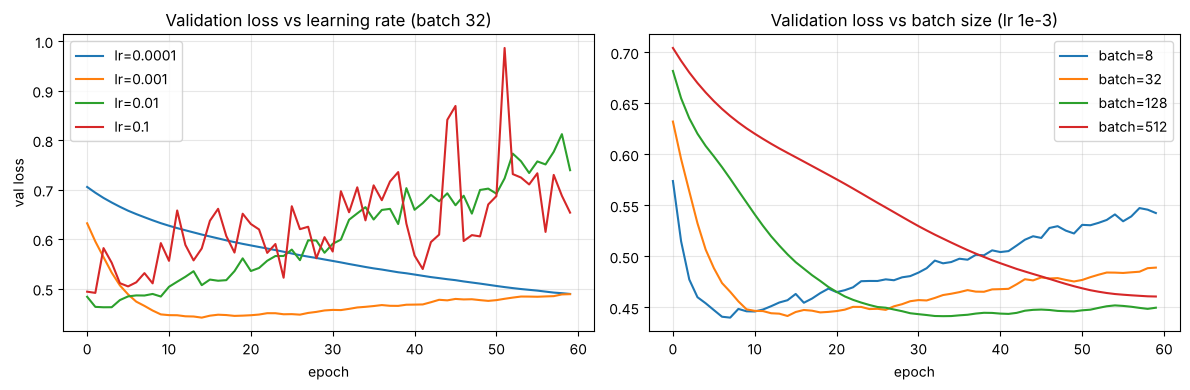

      setting    value  test accuracy  train time (s)  best val loss
learning rate   0.0001         0.7958          8.5372         0.4894
learning rate   0.0010         0.8125          8.7871         0.4416
learning rate   0.0100         0.7708          8.7851         0.4625
learning rate   0.1000         0.8000          8.4667         0.4916
   batch size   8.0000         0.8083         16.0168         0.4400
   batch size  32.0000         0.8125          8.9953         0.4416
   batch size 128.0000         0.8125          6.9994         0.4415
   batch size 512.0000         0.8333          6.2588         0.4607


In [10]:
def run(lr=1e-3, bs=32, epochs=60):
    m = student_net(lr=lr); import time; t = time.time()
    h = m.fit(Xtr, y_tr, validation_split=.2, epochs=epochs, batch_size=bs, verbose=0)
    return h.history, time.time() - t, m.evaluate(Xte, y_te, verbose=0)[1]

fig, ax = plt.subplots(1, 2, figsize=(12, 4)); rows = []
for lr in [1e-4, 1e-3, 1e-2, 1e-1]:
    h, t, acc = run(lr=lr); ax[0].plot(h["val_loss"], label=f"lr={lr}"); rows.append(["learning rate", lr, acc, t, np.min(h["val_loss"])])
for bs in [8, 32, 128, 512]:
    h, t, acc = run(bs=bs); ax[1].plot(h["val_loss"], label=f"batch={bs}"); rows.append(["batch size", bs, acc, t, np.min(h["val_loss"])])
ax[0].set(title="Validation loss vs learning rate (batch 32)", xlabel="epoch", ylabel="val loss"); ax[1].set(title="Validation loss vs batch size (lr 1e-3)", xlabel="epoch")
for a in ax: a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()
exp = pd.DataFrame(rows, columns=["setting", "value", "test accuracy", "train time (s)", "best val loss"]).round(4); print(exp.to_string(index=False))
R["experiments"] = exp.to_dict("records")

**What the experiment shows** (compare the *best validation loss* column; test accuracy on 240 students moves by ±2–3 points from pure noise, so it is not a reliable judge here):
* **Learning rate:** `1e-3` reached the lowest validation loss; `1e-4` is too slow to converge in 60 epochs, and `1e-1` is too aggressive (a worse, noisier minimum).
* **Batch size:** small batches (8) cost about **2× the training time** for no better loss; a huge batch (512 ≈ 2 updates per epoch) is fastest per epoch but learns more slowly per epoch (higher validation loss).
* So learning rate, batch size and epochs have to be tuned **together**; early stopping removes the guesswork on epochs.

### Summary of Day 5
| Idea | Takeaway |
|---|---|
| Neuron | weighted sum + bias → activation |
| Training loop | forward → loss → backprop (chain rule) → gradient-descent update |
| Optimisers | Adam adapts the step per weight; SGD is simple but needs tuning |
| Keras | Sequential → compile → fit → evaluate; use early stopping |
| Reality check | Always compare with a simple baseline |

In [11]:
json.dump(R, open("results.json", "w"), indent=2, default=float); print("results.json saved")

results.json saved
